Descriptive statistics basically means showing how a dataset looks.it gives a general description of quantitative data.
These are also called measures of central tendancy is central data is worked out in this case.

* Mean: The average of the data.

* Median: The central data point.

* Mode: The most repeated value.

In [ ]:
import numpy as np 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import skew, kurtosis

In [ ]:
goals = np.array([0, 1, 2, 1, 0, 3, 1, 2, 0, 1, 4, 2, 1, 0, 5, 1, 0, 2, 8])
counts = pd.Series(goals).value_counts().sort_index()

mean = np.mean(goals).round(4)
print("Mean:",mean)


sorted = np.sort(goals)
median = np.median(sorted)
print("Median:",median)

variance = np.var(goals,ddof = 1).round(4)
print(variance)

std = np.std(goals,ddof = 1).round(4)
print(std)

df = pd.Series(goals)
print(df.value_counts())

mode_value = df.mode()[0] #To pick up the first mode value mode is 1
print("Mode:", mode_value)

* Skewness & Measures of Central Tendency
* Skewness shows which way the data is tilted. In other words, skewness basically reveals whether outliers are present or not.

* If data is positively or negatively skewed, we should look at the median for the central value, because we know the mean gets pulled too high or too low due to the presence of outliers.

* All of these are measures of central tendency, meaning they describe how the data behaves toward the center.

In [ ]:
plt.figure(figsize=(8, 5))
plt.bar(counts.index, counts.values, color='skyblue', edgecolor='black')

range = np.max(goals) - np.min(goals)
print(range)

#We have Positively Skewed value here

skewness_value = df.skew()
print("Skewness :", skewness_value)

Right Skew (Positive): The Mean is greater than the Median Mean > Meadian because the high outliers pull the average up into the right tail.Left Skew (Negative): The Mean is less than the Median Mean < Median because low outliers pull the average down into the left tail.

In [ ]:
sns.boxplot(x = df , color = 'Yellow')
plt.title("Box Plot of Goals")
plt.xlabel("Goals")

* Measures of Dispersion

* Range: The difference between the largest and smallest values. It shows how spread out the data is. However, just because a range is high doesn't mean the whole dataset is generally spread out—it can simply mean that outliers are present.

* Variance: Shows how far away each data point is from the mean.

* Standard Deviation (std): Simply the square root of variance, serving the exact same purpose (in the original units).

In [ ]:
range = np.max(goals) - np.min(goals)
print("Range: ",range)

variance = np.var(goals,ddof = 1)
print(variance)

stdev = np.std(goals,ddof = 1)
print(stdev)

#On average, the matches deviate from the mean by about 2.04 goals (Standard Deviation).

* ddof=0 (Population): Divides by n. Use this only if your dataset contains every single data point that could ever possibly exist.
* ddof=1 (Sample): Divides by n - 1 (called Bessel's correction). Use this whenever you are working with a sample of real-world data (like your 19 football matches), because it corrects the math to prevent your variance from being biased.  

* IQR stands for Interquartile Range.
The middle 50% of the data

In [ ]:
q1,q2,q3 = np.percentile(goals,[25,50,75])

InQuRa = q3 - q1
print(InQuRa)

LL = q1 - InQuRa * 1.5
UL = q3 + InQuRa * 1.5

print(LL,UL)


In [ ]:
sns.histplot(
    goals, 
    discrete=True, 
    color='skyblue', 
    edgecolor='black'
)

In [ ]:
df = pd.read_csv(r"C:\Users\Anbit Bhattarai\Desktop\Stats_For_AI_ML\football_practice.csv")
pd.set_option('display.width', 1000)

print(df.info)

In [ ]:
print(df.isna().sum())

df["city"].fillna("Berlin")


In [ ]:
print(df.duplicated().sum())
df.drop_duplicates()

In [ ]:
df["date"] = pd.to_datetime(df["date"])
print(df)

In [ ]:
print(df["home_score"].describe())
print(df["away_score"].describe())

In [ ]:
total_goals = df["home_score"].sum() + df["away_score"].sum()
print(total_goals)

goal_difference = df["home_score"].sum() - df["away_score"].sum()
print(goal_difference)

In [ ]:
total_goals = df["home_score"] + df["away_score"]
print(total_goals)
print("Mean for total goals",np.mean(total_goals))
print("Median for total goals",np.median(total_goals))
print("Mode for total goals",total_goals.mode()[0])
print("Standard Deviation for total goals",total_goals.std().round(2))


print("For Home Goals")

print("Mean for home goals",df["home_score"].mean())
print("Median for home goals",df["home_score"].median())
print("Mode for home goals",df["home_score"].mode()[0])
print("Standard Deviation for Home goals",df["home_score"].std().round(2))



print("For Away Goals")

print("Mean for away goals",df["away_score"].mean())
print("Median for away goals",df["away_score"].median())
print("Mode for away goals",df["away_score"].mode()[0])
print("Standard Deviation for away goals",df["away_score"].std().round(2))






In [ ]:
LL = q1 - InQuRa * 1.5
UL = q3 + InQuRa * 1.5

print(LL,UL)

print((total_goals > 6).sum())

outliers = (total_goals > UL) | (total_goals < LL)
print(outliers.sum())

In [ ]:
print(df["home_score"].describe())
print(df["away_score"].describe())

In [ ]:
tourney = df.groupby("tournament")
print(tourney["date"].count())
total_goals = tourney["home_score"].sum()+ tourney["away_score"].sum()
print(total_goals)
total_matches = tourney["date"].count()

meany = total_goals/total_matches
print(meany.head(5))

In [ ]:
turf = df.groupby("neutral")
print(turf.count())

home_advantage_df = df.groupby("neutral")[["home_score", "away_score"]].mean()

print(home_advantage_df)

In [ ]:
tourney = df.groupby("tournament")["date"].count()
# print(tourney["date"].count())
# total_goals = tourney["home_score"].sum()+ tourney["away_score"].sum()
# print(total_goals)
# total_matches = tourney["date"].count()

# meany = total_goals/total_matches
# print(meany.head(5))

In [ ]:
plt.bar(tourney.index,tourney.values)
plt.grid()

In [ ]:
plt.bar(df["home_score"],df["home_team"])

# plt.bar(df["away_score"],df["home_team"])

In [ ]:
# Group by team and sum their home scores
team_goals = df.groupby("home_team")["home_score"].sum().sort_values(ascending=True)

# Plot a clean horizontal bar chart
plt.figure(figsize=(8, 10))
team_goals.plot(kind="barh", color="skyblue", edgecolor="black")

plt.title("Total Home Goals by Team")
plt.xlabel("Goals")
plt.ylabel("Team")
plt.show()

away_goals = df.groupby("away_team")["away_score"].sum().sort_values(ascending=True)
plt.figure(figsize = (8,10))
away_goals.plot(kind="barh",color = "Green",edgecolor = "black")
plt.title("Total Away Goals by Team")
plt.xlabel("Goals")
plt.ylabel("Team")
plt.show()

concededing = df.groupby("home_team")["away_score"].sum().sort_values(ascending=True)
plt.figure(figsize = (8,10))
concededing.plot(kind="barh",color = "Green",edgecolor = "black")
plt.title("Total Conceded by Home Team")
plt.xlabel("Goals")
plt.ylabel("Team")
plt.show()

concededing = df.groupby("away_team")["home_score"].sum().sort_values(ascending=True)
plt.figure(figsize = (8,10))
concededing.plot(kind="barh",color = "Green",edgecolor = "black")

plt.title("Total Conceded by Away Team")
plt.xlabel("Goals")
plt.ylabel("Team")
plt.show()

- Symmetrical Distribution : Mean = Median = Mode
- Both sides having same number of data

- Pearson's Coefficient of Skewness: Formula to calculate skewness
PC = (Mean - Mode)/Std

-3 to + 3

- In Case mode is intermediate - (Mean-(3 Median - 2 Mean)/std)
- the mode is intermediate means that the mode sits in between (intermediate to) the mean and the median along the number line.

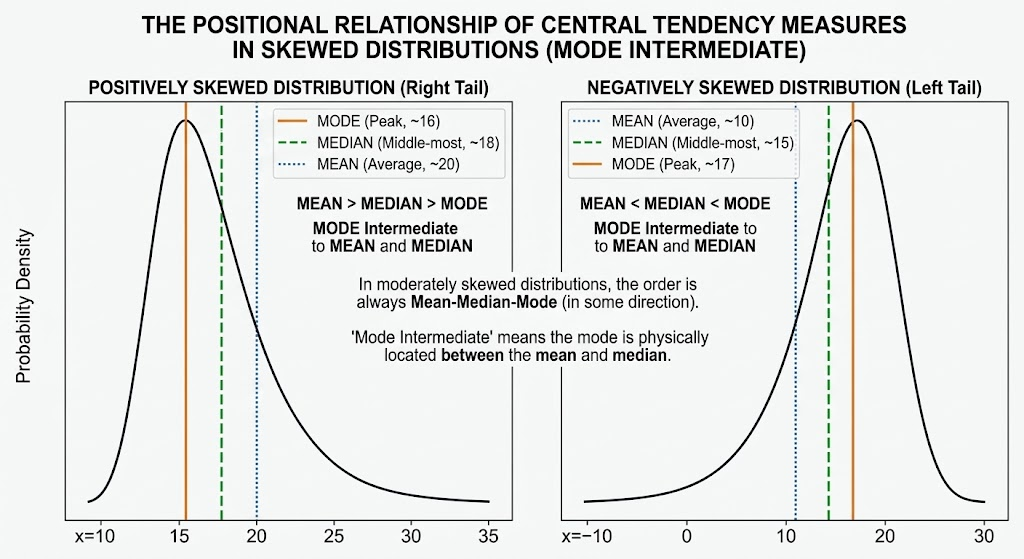

In [ ]:
plt.bar(tourney.values,tourney.index)
plt.tight_layout()

- Kurtosis
-Kurtosis is a statistical measure that describes the shape of a distribution's tails relative to a normal distribution.
- Used to find outliers in data,Used to find the degree of outliers present
- Measures the peakness of a distribution

- if (kurt > 0):When the curve is high it is leptokurtic.
- if (kurt < 0) : When the curve is flat it is platykurtic
- if (kurt = 0) : When the curve is normal

the expected value of kurt is 3
- < 3 Negative Kurtosis
* *> 3 Postive Kurtosis

Skewness measures the asymmetry of your distribution,telling you whether the data stretches out more into a right-side tail or a left-side tail.

Kurtosis measures the peakedness and tail weight,essentially describing how "tall" and sharp the center peak is, and how fat or thin the outer tails (the extremes) are compared to a normal distribution.

In [ ]:


# 1. Create a random dataset
np.random.seed(42)

df = pd.DataFrame({
    "A": np.append(np.random.normal(50, 10, 100), [100, 120]),
    "B": np.append(np.random.normal(100, 15, 100), [180, 200]),
    "C": np.append(np.random.normal(30, 5, 100), [60, 70])
})

# 2. Create three graphs
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 3. Calculate statistics for each column
for ax, col in zip(axes, df.columns):

    data = df[col].dropna()

    # Mean, median, and mode
    mean = data.mean()
    median = data.median()
    mode = data.mode().iloc[0]

    # Quartiles
    Q1, Q2, Q3 = np.percentile(data, [25, 50, 75])

    # IQR and outlier limits
    IQR = Q3 - Q1
    LL = Q1 - 1.5 * IQR
    UL = Q3 + 1.5 * IQR

    # Identify outliers
    outliers = data[(data < LL) | (data > UL)]

    # Skewness and excess kurtosis
    skewness = skew(data)
    kurt = kurtosis(data)

    # 4. Plot histogram
    ax.hist(data, bins=15, color="lightblue", edgecolor="black")

    # Mean, median, and mode
    ax.axvline(mean, color="red", linestyle="--", label="Mean")
    ax.axvline(median, color="green", linestyle="-", label="Median")
    ax.axvline(mode, color="purple", linestyle=":", label="Mode")

    # Quartiles
    ax.axvline(Q1, color="orange", linestyle="--", label="Q1")
    ax.axvline(Q2, color="blue", linestyle="--", label="Q2")
    ax.axvline(Q3, color="brown", linestyle="--", label="Q3")

    # Lower and upper limits
    ax.axvline(LL, color="black", linestyle="-.", label="Lower Limit")
    ax.axvline(UL, color="gray", linestyle="-.", label="Upper Limit")

    ax.set_title(f"Dataset {col}")
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")
    ax.legend(fontsize=7)

    # 5. Print results
    print(f"\n--- Dataset {col} ---")
    print(f"Mean: {mean:.2f}")
    print(f"Median: {median:.2f}")
    print(f"Mode: {mode:.2f}")
    print(f"Q1: {Q1:.2f}")
    print(f"Q2: {Q2:.2f}")
    print(f"Q3: {Q3:.2f}")
    print(f"IQR: {IQR:.2f}")
    print(f"Lower Limit: {LL:.2f}")
    print(f"Upper Limit: {UL:.2f}")
    print(f"Outlier Count: {len(outliers)}")
    print("Outliers:", outliers.tolist())
    print(f"Skewness: {skewness:.4f}")
    print(f"Kurtosis: {kurt:.4f}")

# 6. Display graphs
plt.tight_layout()
plt.show()


In [ ]:
# 5 line summary of the findings

df = pd.read_csv(r"C:\Users\Anbit Bhattarai\Desktop\Stats_For_AI_ML\football_practice.csv")

print(df)

total_matches = df["tournament"].value_counts()

home_goals_total = df.groupby("tournament")["home_score"].sum()
print(home_goals_total)

print("The Mean of Home Goals in ")
# print(total_matches["away_score"])

           date  home_team    away_team  home_score  away_score                    tournament          city               country  neutral
0    2010-01-04    Germany       France           1           1  FIFA World Cup qualification        Munich               Germany    False
1    2010-01-26      India        Egypt           0           3                      Friendly      Istanbul                Turkey     True
2    2010-01-26      India  South Korea           1           3                      Friendly       Kolkata                 India    False
3    2010-03-10      India          USA           0           0                FIFA World Cup         Miami         United States     True
4    2010-04-09     Bhutan        Spain           0           3                      Friendly           NaN         United States     True
..          ...        ...          ...         ...         ...                           ...           ...                   ...      ...
395  2024-11-11  Argentina 